In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

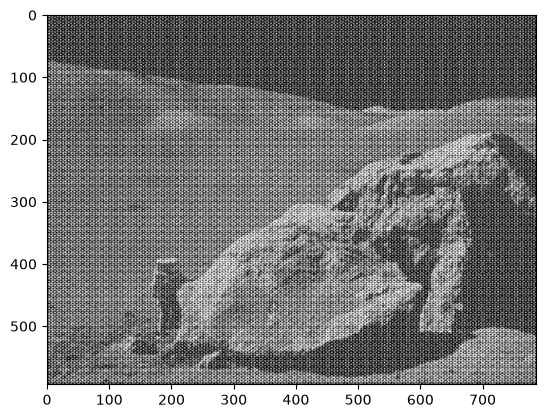

In [2]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

# 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

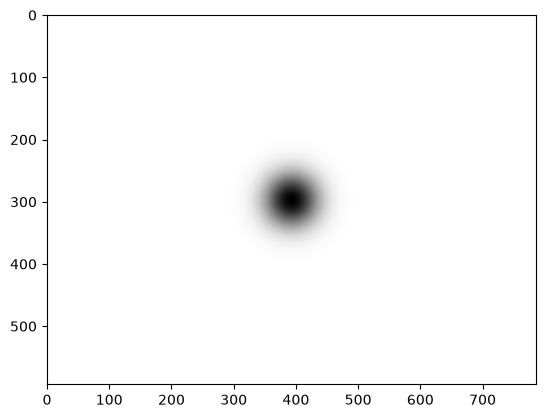

In [3]:
dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

rows, cols = img.shape
x, y = np.meshgrid(np.arange(0, cols, 1), np.arange(0, rows, 1))

sigma = 30

gauss = np.exp(-((x - (cols // 2))**2 + (y - (rows // 2))**2) / (2 * sigma**2))
mask_res = 1 - gauss
plt.imshow(mask_res, cmap='gray')

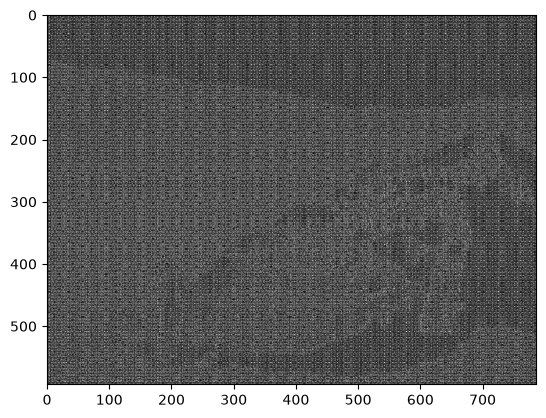

In [4]:
dft_shift = dft_shift * mask_res[:, :, np.newaxis]

img_idft = cv.idft(np.fft.ifftshift(dft_shift))
img_idft = cv.magnitude(img_idft[:, :, 0], img_idft[:, :, 1])

plt.imshow(img_idft, cmap='gray')

# 2. Реализуйте вычисление свертки с помощью преобразования Фурье

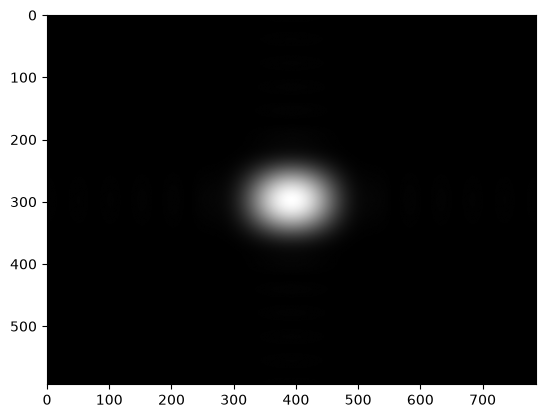

In [5]:
kernel = cv.getGaussianKernel(15, 3)
kernel = np.outer(kernel, kernel)

kernel_pad = np.zeros_like(img, dtype=np.float32)
kh, kw = kernel.shape
kernel_pad[:kh, :kw] = kernel

kernel_pad = np.roll(kernel_pad, -(kh // 2), axis=0)
kernel_pad = np.roll(kernel_pad, -(kw // 2), axis=1)

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_pad, flags=cv.DFT_COMPLEX_OUTPUT)

dft_kernel_shift = np.fft.fftshift(dft_kernel)
kernel_spec = 20 * np.log(cv.magnitude(dft_kernel_shift[:,:,0], dft_kernel_shift[:,:,1]) + 1)

dft_conv = cv.mulSpectrums(dft_img, dft_kernel, 0)

plt.imshow(kernel_spec, cmap='gray')

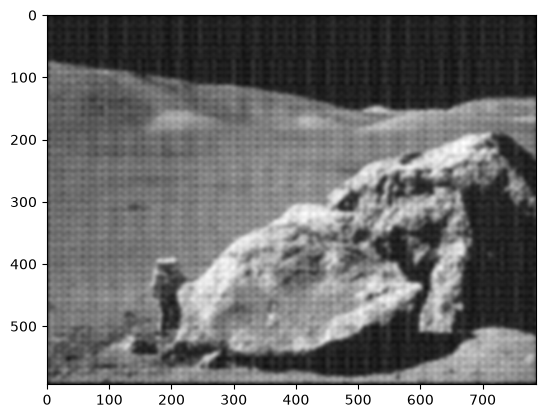

In [6]:
img_idft = cv.idft(dft_conv)
img_idft = cv.magnitude(img_idft[:, :, 0], img_idft[:, :, 1])

plt.imshow(img_idft, cmap='gray')

# 3. Реализуйте удаление периодического шума с помощью преобразования Фурье

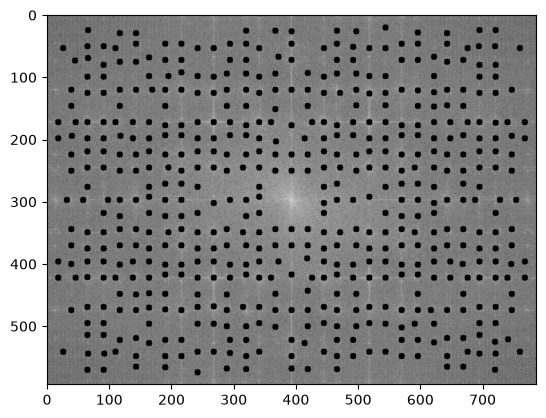

In [8]:
from skimage.feature import peak_local_max

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

local_max = peak_local_max(magnitude_spectrum, min_distance=15, threshold_abs=200)

mask = np.ones((rows, cols, 2), dtype=np.uint8)
center_x, center_y = rows//2, cols//2

for peak in local_max:
    y, x = peak
    distance = np.sqrt((x - center_y)**2 + (y - center_x)**2)
    if distance > 40:  
        cv.circle(mask, (x, y), 5, (0, 0), -1)

dft_shift = dft_shift * mask
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1)

plt.imshow(magnitude_spectrum, cmap='gray')

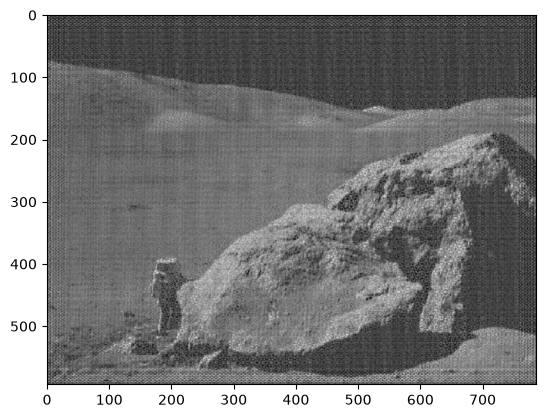

In [9]:
img_idft = cv.idft(np.fft.ifftshift(dft_shift))
img_idft = cv.magnitude(img_idft[:,:,0], img_idft[:,:,1])

plt.imshow(img_idft, cmap='gray')